# Трек 1. Агент в классической среде
Исследовательская задача
Выясните, от чего зависит качество, устойчивость или эффективность RL-агента в стандартной среде.

```
Устойчивость: при каком уровне шума или изменении параметров среды качество начинает заметно снижаться?
Обобщение: справляется ли агент с начальными состояниями или условиями, которых не было при обучении?
Поведение и ошибки: одинаковые ли стратегии выучивают агенты с близкой средней наградой и в каких ситуациях они терпят неудачу?
Функция награды: как её изменение влияет на длительность эпизода, расход ресурса или характер действий?
Эффективность обучения: что при фиксированном бюджете взаимодействий со средой выгоднее: один длинный запуск или несколько коротких запусков с выбором модели по отдельным оценочным эпизодам?
Стабильность: насколько итог зависит от seed и почему отдельные запуски оказываются лучше других?
```


«Агент с высокой обобщающей способностью (топовая модель) показывает стабильные результаты, высокую эффективность независимо от seed среды (начальных состояний), в то время как агент с низкой обобщающей способностью (недообученная/переобученная модель) сильно зависим от случайности среды».

In [1]:
import random
import numpy as np
import psutil
import torch
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from tqdm import trange
from IPython.display import clear_output
from pathlib import Path
from gymnasium.wrappers import RecordVideo
from IPython.display import Video, display
import copy
import sys
%matplotlib inline

In [2]:
print(sys.version)

3.13.13 (main, Apr  7 2026, 20:48:32) [MSC v.1944 64 bit (AMD64)]


In [3]:
if not torch.cuda.is_available():
    # Для маленькой MLP многопоточные накладные расходы на CPU выше выигрыша.
    torch.set_num_threads(1)


def linear_decay(start: float, final: float, step: int, decay_steps: int) -> float:
    fraction = min(max(step / decay_steps, 0.0), 1.0)
    return start + fraction * (final - start)


def is_enough_ram(min_available_gb: float = 0.1) -> bool:
    return psutil.virtual_memory().available >= min_available_gb * 2**30

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# те, у кого есть GPU, но считают несправедливым его использовать, могут раскомментировать:
# device = torch.device('cpu')
device

device(type='cuda')

# Определение агента среды

In [4]:
class DQNAgent(nn.Module):
    def __init__(self, state_shape, n_actions, epsilon=0):
        super().__init__()
        self.epsilon = epsilon
        self.n_actions = n_actions
        self.state_shape = state_shape
        assert len(state_shape) == 1
        state_dim = state_shape[0]

        
        self.fc1=nn.Linear(state_dim,64)
        self.fc2=nn.Linear(64,64)
        self.out=nn.Linear(64,n_actions)


    def forward(self, state_t):
        """Возвращает Q-значения формы [batch_size, n_actions]."""
        
        x=torch.relu(self.fc1(state_t))
        x=torch.relu(self.fc2(x))
        qvalues=self.out(x)
 

        if torch.is_grad_enabled():
            assert qvalues.requires_grad, "qvalues must carry gradients in grad mode"
        assert qvalues.shape == (state_t.shape[0], self.n_actions)
        return qvalues

    @torch.no_grad()
    def get_qvalues(self, states):
        """Вычисляет Q-значения для numpy-массива состояний."""
        model_device = next(self.parameters()).device
        states = torch.as_tensor(np.asarray(states), device=model_device, dtype=torch.float32)
        
        qvalues=self.forward(states)

        return qvalues.cpu().numpy()

    def sample_actions(self, qvalues):
        """Выбирает действия по epsilon-greedy политике."""
        batch_size, n_actions = qvalues.shape
        
        
        best_actions=np.argmax(qvalues,axis=-1)
        random_actions=np.random.choice(n_actions,size=batch_size)

        #Создаём маску масив, которая применяется на весь batch, где тру будем брать лучшее действие, где false случайное действие
        should_explorer=np.random.uniform(0,1,size=batch_size)<=self.epsilon
     
        #Применяем маску
        actions=np.where(should_explorer,random_actions,best_actions)

        return actions




In [5]:

class DuelingDQNHead(nn.Module):
    def __init__(self, input_dim, n_actions):
        super().__init__()
        
       
        self.fc1_dual=nn.Linear(input_dim,128)
        self.fc2_dual=nn.Linear(128,128)
        #self.out=nn.Linear(64,n_actions)
                      
        self.advantage_stream =nn.Linear(128,n_actions)
        self.value_stream = nn.Linear(128,1)


    def forward(self, x):
        
        x=torch.relu(self.fc1_dual(x))
        x=torch.relu(self.fc2_dual(x))
        value=self.value_stream(x)
        advantage=self.advantage_stream(x)
        qvalues=value+(advantage-advantage.mean(dim=1,keepdim=True))

        return qvalues


In [6]:

class DuelingDQN(nn.Module):
    def __init__(self, state_shape, n_actions):
        super().__init__()
        
        state_dim=state_shape[0]
        self.feature_extractor=nn.Sequential(nn.Linear(state_dim,64),nn.ReLU(),)
        self.dueling_head=DuelingDQNHead(64,n_actions)


    def forward(self, x):
        return self.dueling_head(self.feature_extractor(x))


In [7]:

class DuelingDQNAgent(DQNAgent):
    def __init__(self, state_shape, n_actions, epsilon=0):
        nn.Module.__init__(self)
        self.epsilon = epsilon
        self.n_actions = n_actions
        self.state_shape = state_shape
        
        self.network=DuelingDQN(state_shape,n_actions)
    def forward(self, state_t):
       return self.network(state_t)    

### Функция потерь 

In [8]:
def compute_td_loss_double(states, actions, rewards, next_states, is_done,
                           agent, target_network, gamma=0.99,
                           loss_kind="mse", check_shapes=False, device=device):
    states = torch.as_tensor(states, dtype=torch.float32, device=device)
    actions = torch.as_tensor(actions, dtype=torch.int64, device=device)
    rewards = torch.as_tensor(rewards, dtype=torch.float32, device=device)
    next_states = torch.as_tensor(next_states, dtype=torch.float32, device=device)
    is_done = torch.as_tensor(is_done, dtype=torch.bool, device=device)

    predicted_qvalues = agent(states)
    ### ВАШ КОД
    # Значения для реальны выполненых действий
    predictions = predicted_qvalues.gather(1, actions.unsqueeze(1)).squeeze(1)   
  

    with torch.no_grad():
            # Сеть Agent выбирает действия 
            next_qvalues_agent = agent(next_states)
            next_act = next_qvalues_agent.argmax(dim=1,keepdim=True)
            #Для оценки ценности выбранного действия используется целевая сеть
            next_qvalues_target=target_network(next_states)
            next_values=next_qvalues_target.gather(1,next_act).squeeze(1)

                 
            targets = (rewards
                       + gamma * next_values * (~is_done).float()
                   )
    if loss_kind=='mse':
        loss=nn.MSELoss()(predictions,targets)
    if loss_kind=='huber':
        loss=nn.HuberLoss()(predictions,targets)
    
    ### ВАШ КОД ЗАКОНЧИЛСЯ

    if check_shapes:
        assert predictions.shape == rewards.shape
        assert targets.shape == rewards.shape
        assert not targets.requires_grad
    return loss

### Буфер повторов

Интерфейс довольно прост:
* `exp_replay.add(obs, act, rw, next_obs, done)` - сохраняет кортеж (s,a,r,s',done) в буфер
* `exp_replay.sample(batch_size)` - возвращает наблюдения, действия, награды, следующие наблюдения и флаги завершения эпизода для `batch_size` случайных образцов.
* `len(exp_replay)` - возвращает количество элементов, хранящихся в буфере воспроизведения.

In [9]:
class ReplayBuffer(object):
    def __init__(self, size):
        """Создаёт буфер воспроизведения.
        Параметры
        ----------
        size: int
            Максимальное количество переходов, которые можно хранить в буфере.
            При переполнении буфера старые записи удаляются.
        """
        self._storage = []
        self._maxsize = size
        self._next_idx = 0

    def __len__(self):
        return len(self._storage)

    def add(self, obs_t, action, reward, obs_tp1, done):
        data = (obs_t, action, reward, obs_tp1, done)

        if self._next_idx >= len(self._storage):
            self._storage.append(data)
        else:
            self._storage[self._next_idx] = data
        self._next_idx = (self._next_idx + 1) % self._maxsize

    def _encode_sample(self, idxes):
        obses_t, actions, rewards, obses_tp1, dones = [], [], [], [], []
        for i in idxes:
            data = self._storage[i]
            obs_t, action, reward, obs_tp1, done = data
            obses_t.append(np.asarray(obs_t))
            actions.append(np.asarray(action))
            rewards.append(reward)
            obses_tp1.append(np.asarray(obs_tp1))
            dones.append(done)
        return (
            np.array(obses_t),
            np.array(actions),
            np.array(rewards),
            np.array(obses_tp1),
            np.array(dones),
        )

    def sample(self, batch_size):
        """Выбирает случайную партию переходов из буфера.
        Параметры
        ----------
        batch_size: int
            Сколько переходов нужно выбрать.
        Возвращает
        -------
        obs_batch: np.array
            партия наблюдений
        act_batch: np.array
            партия действий, выполненных в состоянии obs_batch
        rew_batch: np.array
            вознаграждения, полученные в результате выполнения act_batch
        next_obs_batch: np.array
            следующие наблюдения после выполнения act_batch
        done_mask: np.array
            done_mask[i] = 1, если выполнение act_batch[i] привело к завершению эпизода,
            и 0 в противном случае.
        """
        idxes = [random.randint(0, len(self._storage) - 1) for _ in range(batch_size)]
        return self._encode_sample(idxes)

### Взаимодействие со средой: `play_and_record`

In [10]:
def play_and_record(initial_state, agent, env, exp_replay, n_steps=1):
    """Делает ровно n_steps взаимодействий и записывает переходы в replay.

    Среда сбрасывается и при terminated, и при truncated. В поле done хранится
    только terminated: ограничение времени не должно обнулять bootstrap-цель.
    """
    state = initial_state
    sum_rewards = 0.0

    ### ВАШ КОД
    for n in range(n_steps):
      qvalues = agent.get_qvalues([state])
      action = agent.sample_actions(qvalues)[0]
      #Получаем информацию от среды
      next_state, reward, terminated, truncated,_ = env.step(action)
      sum_rewards += reward
      #Записываем состояние
      exp_replay.add(state,action,reward,next_state,terminated)
      if terminated or truncated:
        state,_=env.reset()
      else:
         state=next_state
    ### ВАШ КОД ЗАКОНЧИЛСЯ

    return sum_rewards, state

# Функция оценки

In [11]:
MAX_EPISODE_STEPS=1000

In [12]:
def evaluate(env, agent, n_games=1, greedy=False, t_max=MAX_EPISODE_STEPS,
             seed=None, return_rewards=False):
    """Играет независимые эпизоды и возвращает среднюю награду или весь массив.

    При заданном seed эпизоды получают seed, seed + 1, ... и поэтому используют
    воспроизводимые, но различные начальные состояния.
    """
    rewards = []
    for game_idx in range(n_games):
        episode_seed = None if seed is None else seed + game_idx
        state, _ = env.reset(seed=episode_seed)
        total_reward = 0.0
        for _ in range(t_max):
            qvalues = agent.get_qvalues([state])
            action = qvalues.argmax(axis=-1)[0] if greedy else agent.sample_actions(qvalues)[0]
            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            if terminated or truncated:
                break
        rewards.append(total_reward)

    rewards = np.asarray(rewards, dtype=np.float32)
    return rewards if return_rewards else float(rewards.mean())

# Определение среды LunarLander

In [13]:


LUNAR_ENV_NAME = "LunarLander-v3"
LUNAR_MAX_EPISODE_STEPS = 1000


def make_lunar_env(render_mode=None):
    return gym.make(LUNAR_ENV_NAME, continuous=False, render_mode=render_mode)


lunar_probe_env = make_lunar_env()
lunar_state_shape = lunar_probe_env.observation_space.shape
lunar_n_actions = lunar_probe_env.action_space.n
assert lunar_state_shape == (8,)
assert lunar_n_actions == 4
print("Наблюдение:", lunar_state_shape, "действий:", lunar_n_actions)
lunar_probe_env.close()

Наблюдение: (8,) действий: 4


# Гиперпараметры обучения

# Инициализация сети и буфера

In [14]:
### ВАШ КОД
lunar_seed = 42
lunar_replay_size = 150_000
lunar_initial_fill = 10_000
lunar_collect_steps = 100
lunar_batch_size = 256
lunar_total_steps = 200_000
lunar_decay_steps = 60_000
lunar_learning_rate = 1e-3
lunar_init_epsilon = 1.0
lunar_final_epsilon = 0.01
lunar_target_update_freq = 1000
lunar_eval_freq = 5000
lunar_loss_freq = 100
lunar_max_grad_norm = 10.0
lunar_validation_n_games = 20
lunar_validation_seed = 10_000
lunar_validation_std_penalty = 0.25
lunar_validation_reward_threshold = 250.0
lunar_validation_p10_threshold = 150.0
lunar_required_strong_evaluations = 3
### ВАШ КОД ЗАКОНЧИЛСЯ

random.seed(lunar_seed)
np.random.seed(lunar_seed)
torch.manual_seed(lunar_seed)

# Выберите одну из реализаций первой части и функцию потерь.
### ВАШ КОД
lunar_train_dueling = True
lunar_reinitialize_network = True
lunar_loss_kind = "huber"  # допустимы "huber" и "mse"
### ВАШ КОД ЗАКОНЧИЛСЯ

lunar_agent_class = DuelingDQNAgent if lunar_train_dueling else DQNAgent
lunar_agent = lunar_agent_class(
    lunar_state_shape, lunar_n_actions, epsilon=lunar_init_epsilon).to(device)
lunar_target = lunar_agent_class(
    lunar_state_shape, lunar_n_actions, epsilon=0.0
).to(device)


def reset_trainable_layer(module):
    if hasattr(module, "reset_parameters"):
        module.reset_parameters()


if lunar_reinitialize_network:
    lunar_agent.apply(reset_trainable_layer)
lunar_target.load_state_dict(lunar_agent.state_dict())
lunar_optimizer = torch.optim.Adam(
    lunar_agent.parameters(), lr=lunar_learning_rate
)

lunar_replay = ReplayBuffer(lunar_replay_size)
lunar_fill_env = make_lunar_env()
lunar_state, _ = lunar_fill_env.reset(seed=lunar_seed)
while len(lunar_replay) < lunar_initial_fill:
    _, lunar_state = play_and_record(
        lunar_state, lunar_agent, lunar_fill_env, lunar_replay,
        n_steps=lunar_collect_steps,
    )
lunar_fill_env.close()
print("Размер LunarLander replay buffer:", len(lunar_replay))

Размер LunarLander replay buffer: 10000


In [15]:
dueling_opt = torch.optim.Adam(
    lunar_agent.parameters(), lr=lunar_learning_rate
)
lunar_eval_steps, lunar_rewards = [], []
lunar_reward_stds, lunar_reward_p10 = [], []
lunar_losses, lunar_loss_steps = [], []
lunar_grad_norms, lunar_initial_values = [], []
lunar_best_selection = -np.inf
lunar_best_mean = -np.inf
lunar_best_std = np.inf
lunar_best_p10 = -np.inf
lunar_best_step = 0
lunar_best_state = copy.deepcopy(lunar_agent.state_dict())
lunar_strong_streak = 0

# Цикл обучения


In [16]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Используем устройство: {device}")

lunar_agent.to(device)
lunar_target.to(device)



Используем устройство: cuda


DuelingDQNAgent(
  (network): DuelingDQN(
    (feature_extractor): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): ReLU()
    )
    (dueling_head): DuelingDQNHead(
      (fc1_dual): Linear(in_features=64, out_features=128, bias=True)
      (fc2_dual): Linear(in_features=128, out_features=128, bias=True)
      (advantage_stream): Linear(in_features=128, out_features=4, bias=True)
      (value_stream): Linear(in_features=128, out_features=1, bias=True)
    )
  )
)

In [17]:
lunar_eval_steps, lunar_rewards = [], []
lunar_reward_stds, lunar_reward_p10 = [], []
lunar_losses, lunar_loss_steps = [], []
lunar_grad_norms, lunar_initial_values = [], []
lunar_best_selection = -np.inf
lunar_best_mean = -np.inf
lunar_best_std = np.inf
lunar_best_p10 = -np.inf
lunar_best_step = 0
lunar_best_state = copy.deepcopy(lunar_agent.state_dict())
lunar_strong_streak = 0

lunar_train_env = make_lunar_env()
lunar_state, _ = lunar_train_env.reset(seed=lunar_seed + 1)
for lunar_step in trange(1, lunar_total_steps + 1):
    lunar_agent.epsilon = linear_decay(
        lunar_init_epsilon, lunar_final_epsilon,
        lunar_step, lunar_decay_steps,
    )
    _, lunar_state = play_and_record(
        lunar_state, lunar_agent, lunar_train_env, lunar_replay, n_steps=1
    )

    ### ВАШ КОД
    lunar_batch =lunar_replay.sample(lunar_batch_size)
    lunar_loss = compute_td_loss_double(*lunar_batch,lunar_agent,lunar_target,loss_kind=lunar_loss_kind)
    ### ВАШ КОД ЗАКОНЧИЛСЯ

    lunar_optimizer.zero_grad(set_to_none=True)
    lunar_loss.backward()
    lunar_grad_norm = nn.utils.clip_grad_norm_(
        lunar_agent.parameters(), lunar_max_grad_norm
    )
    lunar_optimizer.step()

    if lunar_step % lunar_loss_freq == 0:
        lunar_loss_steps.append(lunar_step)
        lunar_losses.append(float(lunar_loss.detach().cpu()))
        lunar_grad_norms.append(float(lunar_grad_norm))

    if lunar_step % lunar_target_update_freq == 0:
        ### ВАШ КОД
        lunar_target.load_state_dict(lunar_agent.state_dict())
        ### ВАШ КОД ЗАКОНЧИЛСЯ

    if lunar_step % lunar_eval_freq == 0:
        current_seed = lunar_validation_seed + lunar_step
        lunar_eval_env = make_lunar_env()
        scores = evaluate(
            lunar_eval_env,
            lunar_agent,
            n_games=lunar_validation_n_games,
            greedy=True,
            t_max=LUNAR_MAX_EPISODE_STEPS,
            seed=current_seed,
            return_rewards=True,
        )
        lunar_eval_env.close()
        mean_score = float(scores.mean())
        std_score = float(scores.std())
        p10_score = float(np.percentile(scores, 10))
        selection_score = mean_score - lunar_validation_std_penalty * std_score

        probe_env = make_lunar_env()
        initial_state = probe_env.reset(seed=20_000 + lunar_step)[0]
        lunar_initial_values.append(
            float(lunar_agent.get_qvalues([initial_state]).max())
        )
        probe_env.close()

        lunar_eval_steps.append(lunar_step)
        lunar_rewards.append(mean_score)
        lunar_reward_stds.append(std_score)
        lunar_reward_p10.append(p10_score)

        if selection_score > lunar_best_selection:
            lunar_best_selection = selection_score
            lunar_best_mean = mean_score
            lunar_best_std = std_score
            lunar_best_p10 = p10_score
            lunar_best_step = lunar_step
            lunar_best_state = copy.deepcopy(lunar_agent.state_dict())

        is_strong = (
            mean_score >= lunar_validation_reward_threshold
            and p10_score >= lunar_validation_p10_threshold
        )
        lunar_strong_streak = lunar_strong_streak + 1 if is_strong else 0
        clear_output(True)
        print(
            f"step={lunar_step}, validation={mean_score:.1f}±{std_score:.1f}, "
            f"p10={p10_score:.1f}, best={lunar_best_mean:.1f}±{lunar_best_std:.1f}"
        )
        if lunar_strong_streak >= lunar_required_strong_evaluations:
            print("Ранняя остановка: устойчивый результат подтверждён")
            break

lunar_train_env.close()
lunar_agent.load_state_dict(lunar_best_state)
lunar_target.load_state_dict(lunar_best_state)
print(
    f"Восстановлен checkpoint: step={lunar_best_step}, "
    f"validation={lunar_best_mean:.1f}±{lunar_best_std:.1f}, "
    f"p10={lunar_best_p10:.1f}"
)

100%|██████████| 200000/200000 [11:51<00:00, 281.11it/s]

step=200000, validation=100.7±124.0, p10=-18.4, best=250.7±36.8
Восстановлен checkpoint: step=155000, validation=250.7±36.8, p10=227.1


Финал: mean=264.1, std=32.4, median=269.4, p10=232.2, min=181.1, max=316.3
Доля эпизодов >= 200: 93.3%


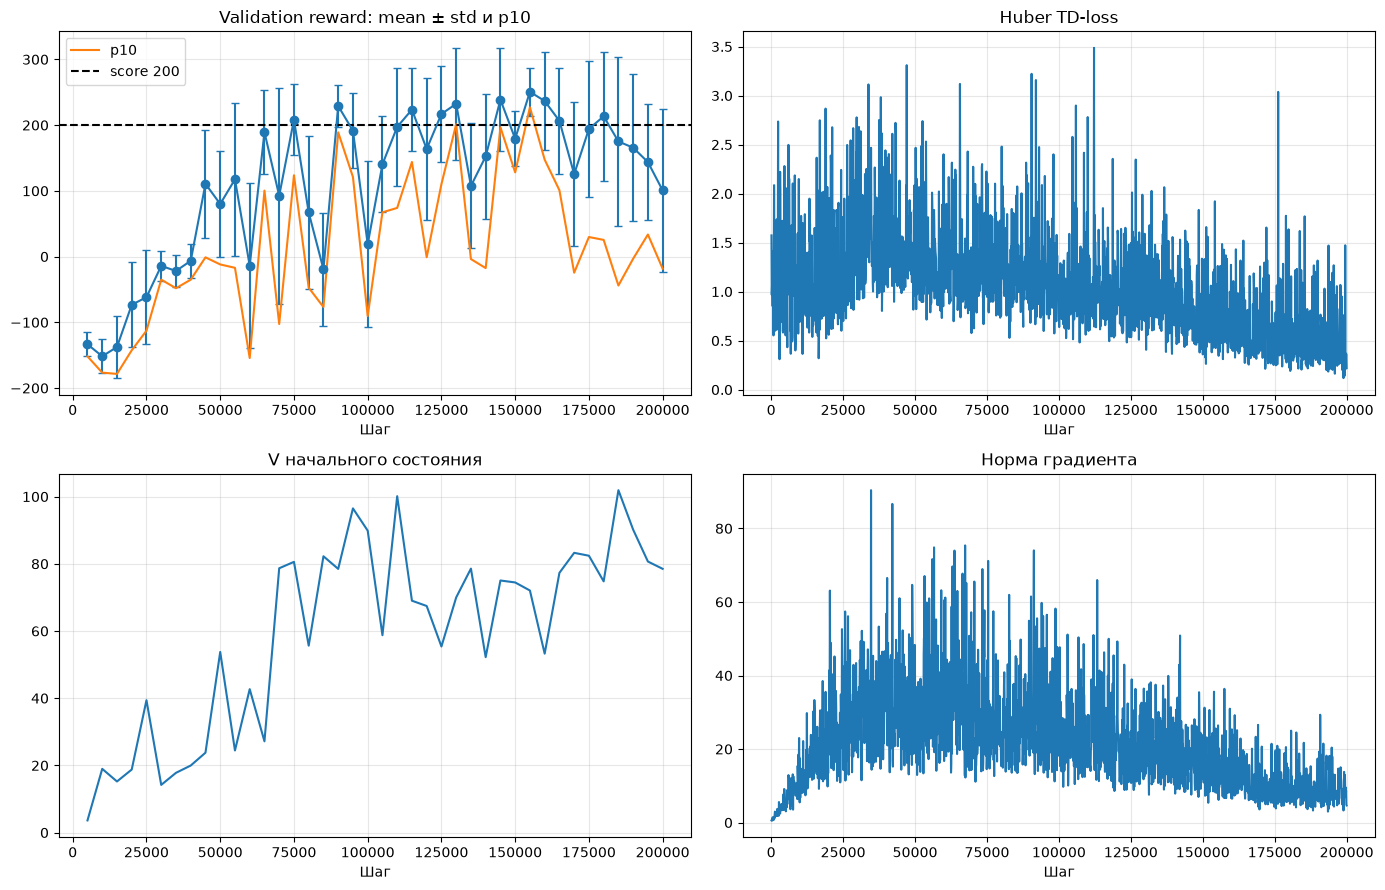

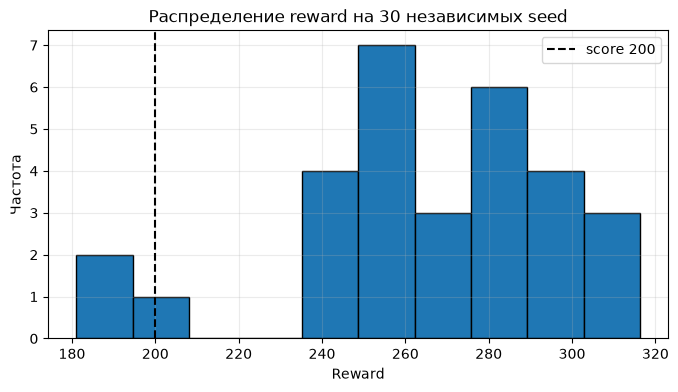

In [18]:
### ВАШ КОД
lunar_final_n_games = 30
lunar_final_seed = 42_000
lunar_score_threshold = 200.0
### ВАШ КОД ЗАКОНЧИЛСЯ

lunar_final_env = make_lunar_env()
lunar_final_scores = evaluate(
    lunar_final_env,
    lunar_agent,
    n_games=lunar_final_n_games,
    greedy=True,
    t_max=LUNAR_MAX_EPISODE_STEPS,
    seed=lunar_final_seed,
    return_rewards=True,
)
lunar_final_env.close()
print(
    f"Финал: mean={lunar_final_scores.mean():.1f}, "
    f"std={lunar_final_scores.std():.1f}, "
    f"median={np.median(lunar_final_scores):.1f}, "
    f"p10={np.percentile(lunar_final_scores, 10):.1f}, "
    f"min={lunar_final_scores.min():.1f}, max={lunar_final_scores.max():.1f}"
)
print(
    f"Доля эпизодов >= {lunar_score_threshold:.0f}: "
    f"{(lunar_final_scores >= lunar_score_threshold).mean():.1%}"
)
if lunar_final_scores.mean() < lunar_score_threshold:
    print(
        "Порог 200 пока не достигнут: Run All продолжается, чтобы графики "
        "помогли диагностировать обучение. Баллы за устойчивое решение требуют "
        "mean >= 200 на этих независимых seed."
    )

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].errorbar(
    lunar_eval_steps, lunar_rewards, yerr=lunar_reward_stds,
    marker="o", capsize=3,
)
axes[0, 0].plot(lunar_eval_steps, lunar_reward_p10, label="p10")
axes[0, 0].axhline(200, color="black", linestyle="--", label="score 200")
axes[0, 0].set(title="Validation reward: mean ± std и p10", xlabel="Шаг")
axes[0, 0].legend()
axes[0, 1].plot(lunar_loss_steps, lunar_losses)
axes[0, 1].set(title="Huber TD-loss", xlabel="Шаг")
axes[1, 0].plot(lunar_eval_steps, lunar_initial_values)
axes[1, 0].set(title="V начального состояния", xlabel="Шаг")
axes[1, 1].plot(lunar_loss_steps, lunar_grad_norms)
axes[1, 1].set(title="Норма градиента", xlabel="Шаг")
for ax in axes.flat:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

plt.figure(figsize=(8, 4))
plt.hist(lunar_final_scores, bins=10, edgecolor="black")
plt.axvline(200, color="black", linestyle="--", label="score 200")
plt.title("Распределение reward на 30 независимых seed")
plt.xlabel("Reward")
plt.ylabel("Частота")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

In [19]:
MAX_EPISODE_STEPS = 1000

In [20]:
### ВАШ КОД
lunar_video_seed = 90_001
lunar_video_folder = Path("videos_lunarlander")
### ВАШ КОД ЗАКОНЧИЛСЯ

lunar_video_env = RecordVideo(
    make_lunar_env(render_mode="rgb_array"),
    video_folder=str(lunar_video_folder),
    episode_trigger=lambda episode_number: episode_number == 0,
    name_prefix="final-lunarlander",
    disable_logger=True,
)
lunar_video_score = evaluate(
    lunar_video_env,
    lunar_agent,
    n_games=1,
    greedy=True,
    t_max=LUNAR_MAX_EPISODE_STEPS,
    seed=lunar_video_seed,
)
lunar_video_env.close()
lunar_video_paths = sorted(
    lunar_video_folder.glob("final-lunarlander*.mp4"),
    key=lambda path: path.stat().st_mtime,
)
assert lunar_video_paths, "Видео LunarLander не было создано"
print(f"Reward финального видео LunarLander: {lunar_video_score:.1f}")
display(Video(str(lunar_video_paths[-1]), embed=True))

c:\Users\Andrey\virtualEnvPython\RLenv\RLvenv\Lib\site-packages\gymnasium\wrappers\rendering.py:298: UserWarning: WARN: Overwriting existing videos at c:\git\RL_TRACK_SW\videos_lunarlander folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Reward финального видео LunarLander: 273.9


In [21]:
def play_and_log_episode(env, agent, seed=None, max_steps=MAX_EPISODE_STEPS):
    state, _ = env.reset(seed=seed)
    log = {key: [] for key in (
        "states", "qvalues", "actions", "rewards", "next_states",
        "terminated", "truncated",
    )}
    for _ in range(max_steps):
        qvalues = agent.get_qvalues([state])[0]
        action = int(np.argmax(qvalues))
        next_state, reward, terminated, truncated, _ = env.step(action)
        values = (state, qvalues, action, reward, next_state, terminated, truncated)
        for key, value in zip(log, values):
            log[key].append(value)
        state = next_state
        if terminated or truncated:
            break
    return {key: np.asarray(value) for key, value in log.items()}

In [22]:
def get_discounted_returns(rewards, gamma, bootstrap_value=0.0) -> np.ndarray:
    """Возвращает G[t]; bootstrap_value используется после последней награды."""
  
    returns = np.zeros_like(rewards,dtype=np.float32)
    g=bootstrap_value
    # По массиву наград в обратном порядке
    for t in reversed(range(len(rewards))):
        g=rewards[t]+gamma*g
        returns[t]=g
    return returns
 

Эпизод 1: return=241.24, шагов=192
Эпизод 2: return=235.57, шагов=293
Эпизод 3: return=266.16, шагов=190
Эпизод 4: return=289.81, шагов=233
Эпизод 5: return=213.56, шагов=297


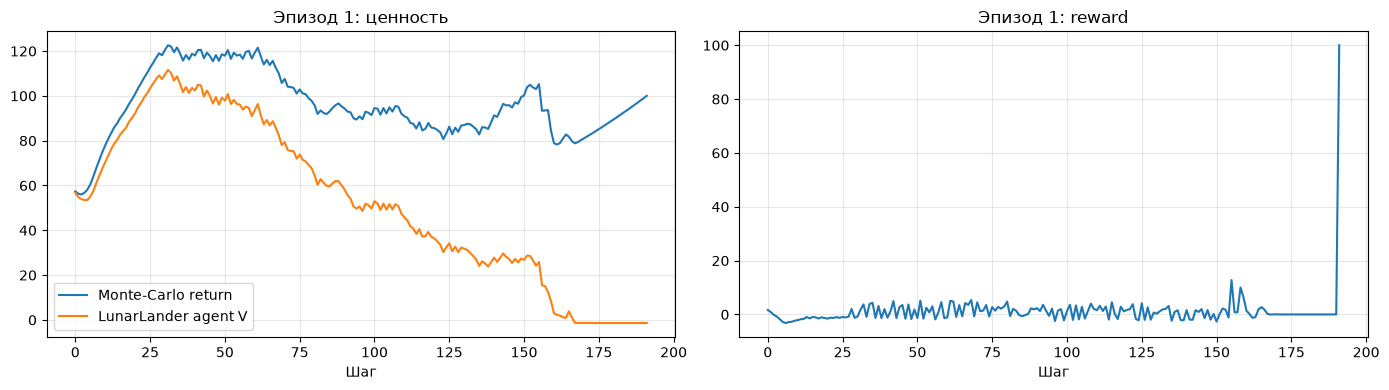

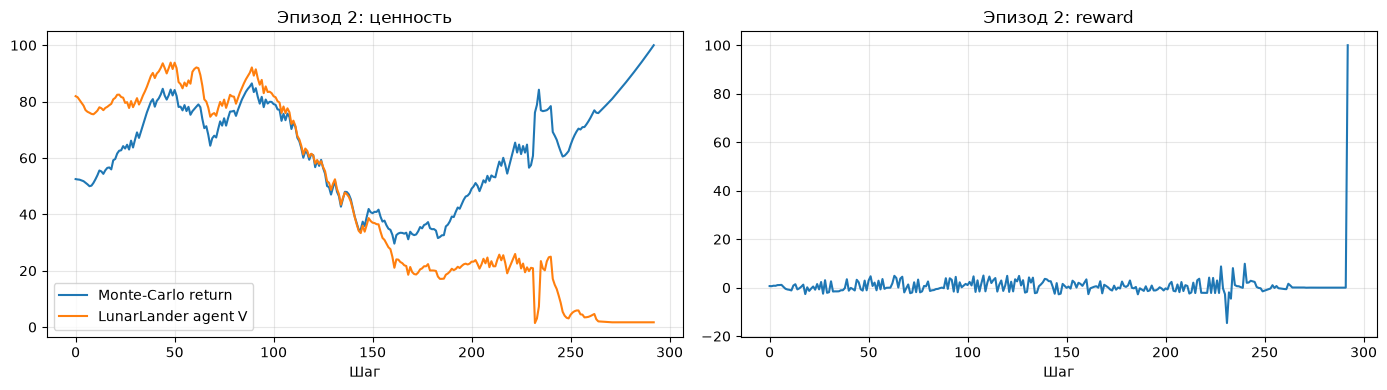

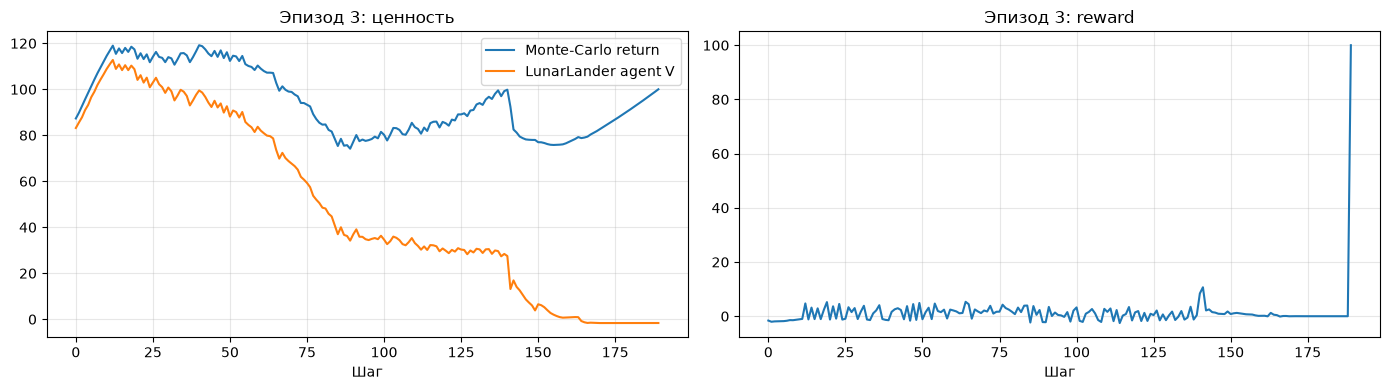

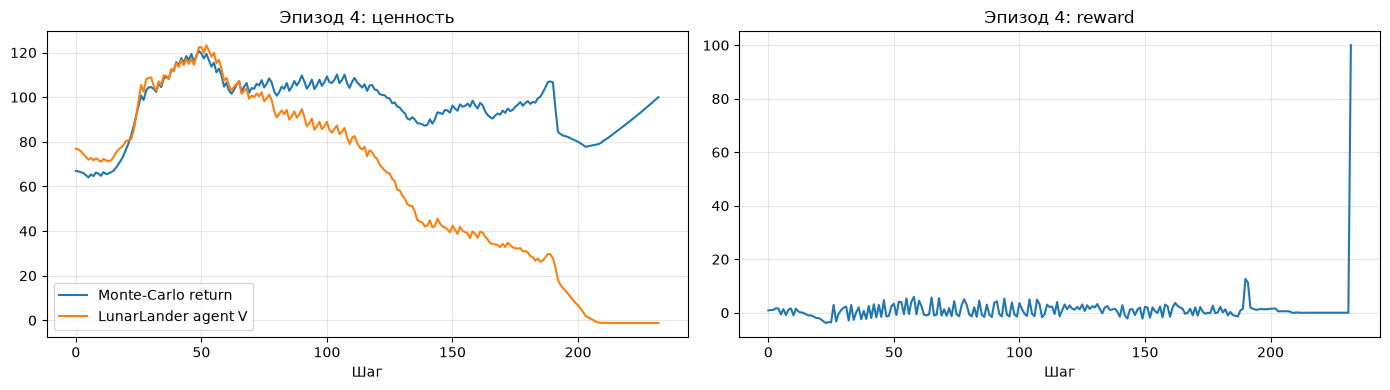

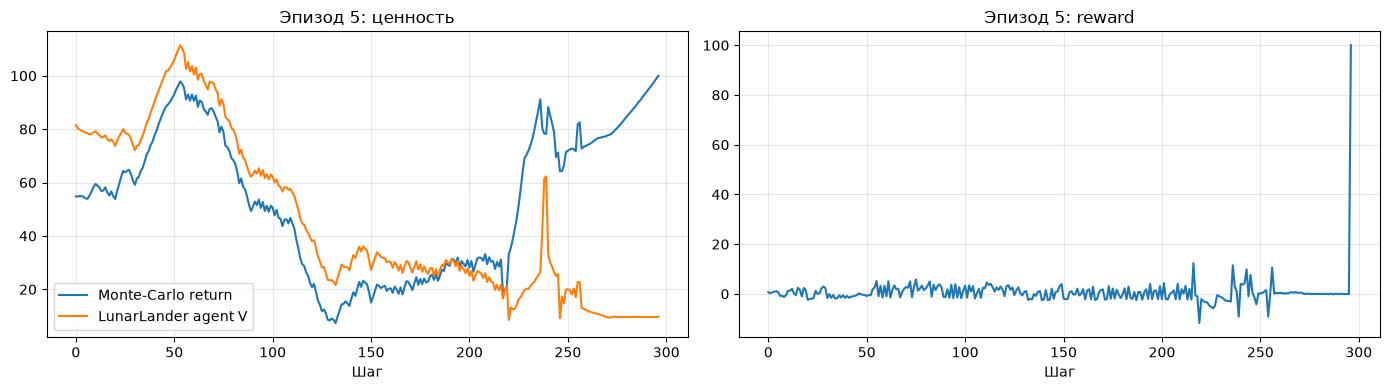

In [23]:

lunar_analysis_n_episodes = 5
lunar_analysis_seed = 250_001
lunar_gamma = 0.99


lunar_records = []
lunar_analysis_env = make_lunar_env()
for episode_idx in range(lunar_analysis_n_episodes):
    record = play_and_log_episode(
        lunar_analysis_env,
        lunar_agent,
        seed=lunar_analysis_seed + episode_idx,
        max_steps=LUNAR_MAX_EPISODE_STEPS,
    )
    lunar_records.append(record)
    print(
        f"Эпизод {episode_idx + 1}: return={record['rewards'].sum():.2f}, "
        f"шагов={len(record['rewards'])}"
    )
lunar_analysis_env.close()

for episode_idx, record in enumerate(lunar_records, start=1):
    mc_return = get_discounted_returns(record["rewards"], lunar_gamma)
    values = record["qvalues"].max(axis=1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(mc_return, label="Monte-Carlo return")
    axes[0].plot(values, label="LunarLander agent V")
    axes[0].set(title=f"Эпизод {episode_idx}: ценность", xlabel="Шаг")
    axes[0].legend()
    axes[1].plot(record["rewards"])
    axes[1].set(title=f"Эпизод {episode_idx}: reward", xlabel="Шаг")
    for ax in axes:
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

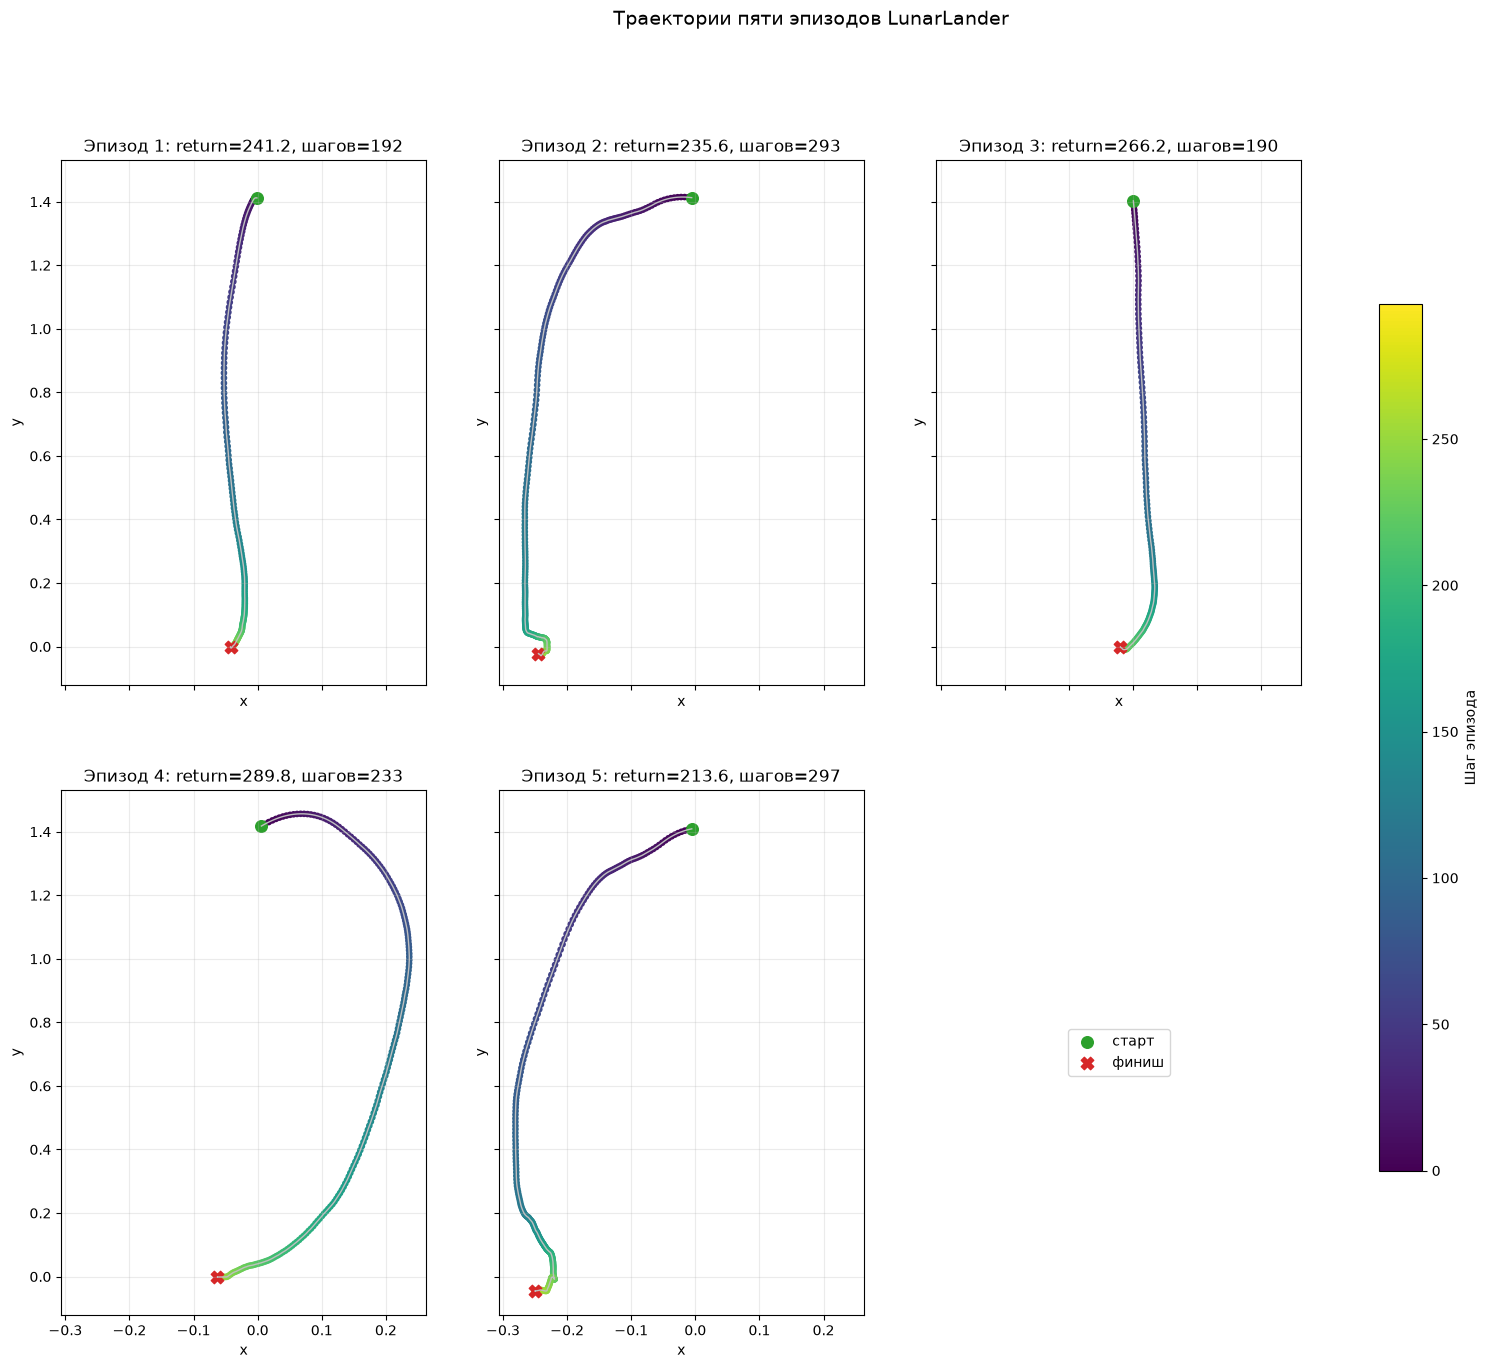

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(20, 15), sharex=True, sharey=True)
for episode_idx, (ax, record) in enumerate(
    zip(axes.flat, lunar_records), start=1
):
    positions = record["states"][:, :2]
    steps = np.arange(len(positions))
    ax.plot(positions[:, 0], positions[:, 1], color="0.75", linewidth=1)
    scatter = ax.scatter(
        positions[:, 0], positions[:, 1], c=steps, cmap="viridis", s=14
    )
    ax.scatter(*positions[0], marker="o", s=70, color="tab:green", label="старт")
    ax.scatter(*positions[-1], marker="X", s=80, color="tab:red", label="финиш")
    ax.set_title(
        f"Эпизод {episode_idx}: return={record['rewards'].sum():.1f}, "
        f"шагов={len(positions)}"
    )
    ax.set(xlabel="x", ylabel="y")
    ax.grid(alpha=0.25)
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center")
fig.colorbar(scatter, ax=axes.ravel().tolist(), label="Шаг эпизода", shrink=0.75)
fig.suptitle("Траектории пяти эпизодов LunarLander", fontsize=14)
plt.show()
plt.close(fig)